# Comprensión y EDA

# Comprensión de datos y Análisis Exploratorio (EDA)


Librerias que se van a utilizar

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [14]:
df = pd.read_csv("../Base_de_datos.csv", parse_dates=["fecha_prestamo"])
df.shape

(10763, 23)

In [15]:
resumen = pd.DataFrame({
    "tipo_dato": df.dtypes,
    "valores_unicos": df.nunique(),
    "ejemplo": df.iloc[0]
})
resumen

,tipo_dato,valores_unicos,ejemplo
tipo_credito,int64,6,4
fecha_prestamo,datetime64[us],10758,2025-01-07 14:40:36
capital_prestado,float64,7306,1852560.0
plazo_meses,int64,18,12
edad_cliente,int64,54,32
tipo_laboral,str,2,Empleado
salario_cliente,int64,1385,3500000
total_otros_prestamos,int64,1538,1000000
cuota_pactada,int64,9836,128650
puntaje,float64,248,95.227787


### Caracterización de variables

| Variable | Clasificación | Observación |
|---|---|---|
| `tipo_credito` | Categórica nominal politómica | Es un código (4, 9, 10, 6, 7, 68), no una cantidad |
| `fecha_prestamo` | Fecha | Se convirtió a tipo fecha al cargar |
| `capital_prestado` | Numérica continua | |
| `plazo_meses` | Numérica discreta | |
| `edad_cliente` | Numérica discreta | |
| `tipo_laboral` | Categórica nominal dicotómica | Empleado / Independiente |
| `salario_cliente` | Numérica continua | |
| `total_otros_prestamos` | Numérica continua | |
| `cuota_pactada` | Numérica continua | |
| `puntaje` | Numérica continua | Puntaje interno |
| `puntaje_datacredito` | Numérica discreta | Puntaje de buró de crédito |
| `cant_creditosvigentes` | Numérica discreta | |
| `huella_consulta` | Numérica discreta | Número de consultas en centrales de riesgo |
| `saldo_mora` | Numérica continua | |
| `saldo_total` | Numérica continua | |
| `saldo_principal` | Numérica continua | |
| `saldo_mora_codeudor` | Numérica continua | Solo 4 valores distintos|
| `creditos_sectorFinanciero` | Numérica discreta | |
| `creditos_sectorCooperativo` | Numérica discreta | |
| `creditos_sectorReal` | Numérica discreta | |
| `promedio_ingresos_datacredito` | Numérica continua | |
| `tendencia_ingresos` | Categórica ordinal politómica | Decreciente < Estable < Creciente →  Es Ordinal 
| `Pago_atiempo` | Categórica dicotómica | **Variable objetivo** (1 = pagó a tiempo, 0 = no) |

### Unificación de valores nulos

Se empieza con la variable `tendencia_ingresos` ya que nos muestra 46 posibles valores cuando teniendo una logica solo serian 3 variables ya que la tendencia de los ingresos serian Creciennte, Decreciente o Estables 

In [16]:
df["tendencia_ingresos"].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
-435177           1
-702927           1
-4105             1
54683             1
22832             1
209090            1
5697              1
-288              1
-164315           1
2029000           1
17181             1
15245             1
82657             1
52862             1
1817052           1
75761             1
146918            1
1123000           1
15090             1
4250635           1
22363             1
-101368           1
86286             1
65988             1
77975             1
-224714           1
10808             1
Name: count, dtype: int64

In [17]:
categorias_validas = ["Creciente", "Estable", "Decreciente"]

df["tendencia_ingresos"] = df["tendencia_ingresos"].where(
    df["tendencia_ingresos"].isin(categorias_validas)
)

df["tendencia_ingresos"].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

**Decisión:**
 Se conservan únicamente las categorías Creciente, Decreciente y Estable de la variable `tendencia_ingresos`. Los demás valores se tratan como nulos (`NaN`), ya que no hay suficiente información para asignarlos a una de las tres categorías.

**Justificación:**
- Semánticamente, una tendencia de ingresos solo puede crecer, decrecer o mantenerse estable.
- Estas tres categorías concentran el 99,3 % de los registros no nulos.
- Los 58 registros restantes (0,7 %) son valores numéricos, incluso negativos, sin relación con una tendencia; probablemente se deben a un error de carga.

Se reemplazan por `NaN` en lugar de eliminar las filas, para no perder la información de las demás variables. Los nulos de esta columna pasan de 2.932 a 2.990.

In [18]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
tipo_credito,10763.0,5.411131,4.0,4.0,4.0,9.0,68.0,2.338279
fecha_prestamo,10763,2025-04-16 23:06:02.111121,2024-11-26 09:17:04,2025-01-20 17:33:07.500000,2025-03-27 16:23:12,2025-06-16 13:27:58,2026-04-26 18:43:52,NaN
capital_prestado,10763.0,2434315.001319,360000.0,1224831.0,1921920.0,3084840.0,41444152.8,1909642.758997
plazo_meses,10763.0,10.575583,2.0,6.0,10.0,12.0,90.0,6.632082
edad_cliente,10763.0,43.94862,19.0,33.0,42.0,53.0,123.0,15.060877
salario_cliente,10763.0,17216431.459909,0.0,2000000.0,3000000.0,4875808.0,22000000000.0,355476717.603482
total_otros_prestamos,10763.0,6238869.648518,0.0,500000.0,1000000.0,2000000.0,6787675263.0,118418316.941069
cuota_pactada,10763.0,243617.406671,23944.0,121041.5,182863.0,287833.5,3816752.0,210493.694608
puntaje,10763.0,91.170036,-38.00999,95.227787,95.227787,95.227787,95.227787,16.465441
puntaje_datacredito,10757.0,780.790834,-7.0,757.0,791.0,825.0,999.0,104.878031


In [19]:
# Edades imposibles mayores a 100 años
df.loc[df["edad_cliente"] > 100, "edad_cliente"] = np.nan

# Puntaje Datacrédito fuera del rango oficial de Colombia (150 a 950)
fuera_rango = (df["puntaje_datacredito"] < 150) | (df["puntaje_datacredito"] > 950)
df.loc[fuera_rango, "puntaje_datacredito"] = np.nan

# Salario en 0 = dato no registrado
df.loc[df["salario_cliente"] == 0, "salario_cliente"] = np.nan

# Verificación
df[["edad_cliente", "puntaje_datacredito", "salario_cliente"]].isnull().sum()

edad_cliente           150
puntaje_datacredito    159
salario_cliente         24
dtype: int64

In [20]:
porcentaje_valor_frecuente = df.apply(
    lambda columna: columna.value_counts(normalize=True).iloc[0] * 100
).round(2)

porcentaje_valor_frecuente.sort_values(ascending=False).head(8)

saldo_mora_codeudor           99.97
saldo_mora                    99.48
Pago_atiempo                  95.25
puntaje                       87.40
creditos_sectorCooperativo    82.39
tipo_credito                  71.98
tendencia_ingresos            68.11
tipo_laboral                  62.75
dtype: float64

**Interpretación:**
 Estos datos nos muestran que proporción de registros comparte el valor más frecuente de cada variable. Valores superiores al 95-99 % indican variables casi constantes, que podrían no aportar información al modelo. 


In [21]:
for columna in ["saldo_mora", "saldo_mora_codeudor"]:
    print(columna)
    print(df.groupby(df[columna] > 0)["Pago_atiempo"].agg(["count", "mean"]))
    print()

saldo_mora
            count      mean
saldo_mora                 
False       10708  0.954146
True           55  0.636364

saldo_mora_codeudor
                     count      mean
saldo_mora_codeudor                 
False                10760  0.952509
True                     3  1.000000



In [22]:
df = df.drop(columns=["saldo_mora_codeudor"])
df.shape

(10763, 22)

### Eliminación de variables irrelevantes
`saldo_mora_codeudor` se elimina: el 99,97 % de los registros con dato tiene valor 0 solo 3 clientes tienen un valor distinto, lo que no permite aprender ningún patrón.

`saldo_mora` se conserva: aunque el 99,48 % de los registros es 0, los 55 clientes con saldo en mora pagan a tiempo en un 64 %, frente al 95 % del resto. Es una variable informativa para identificar clientes morosos.

`fecha_prestamo` se conserva:no se usará directamente como predictor, pero es útil para el análisis temporal y el monitoreo del modelo.

In [23]:
# Categóricas nominales
df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")

# Categórica ordinal (con orden definido)
df["tendencia_ingresos"] = pd.Categorical(
    df["tendencia_ingresos"],
    categories=["Decreciente", "Estable", "Creciente"],
    ordered=True
)

df.dtypes

tipo_credito                           category
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                            float64
tipo_laboral                           category
salario_cliente                         float64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           float64
tendencia_ingresos                     c

### Corrección de tipos de datos
- `tipo_credito` y `tipo_laboral` se convierten a tipo `category` por ser categóricas nominales (los valores de `tipo_credito` son códigos, no cantidades).
- `tendencia_ingresos` se convierte a categoría ordenada (Decreciente < Estable < Creciente) por ser ordinal.
- `fecha_prestamo` ya se cargó como fecha.
- `edad_cliente` y `salario_cliente` pasaron de entero a decimal al incluir `NaN`
- `Pago_atiempo` se mantiene como entero (0/1)

## Análisis univariable

Variable objetivo: `Pago_atiempo`


              clientes  porcentaje_%
Pago_atiempo                        
1                10252         95.25
0                  511          4.75


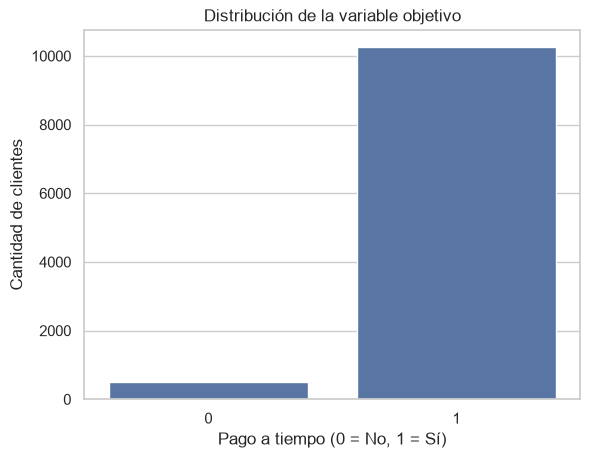

In [24]:
conteo = df["Pago_atiempo"].value_counts()
porcentaje = df["Pago_atiempo"].value_counts(normalize=True) * 100
print(pd.DataFrame({"clientes": conteo, "porcentaje_%": porcentaje.round(2)}))

sns.countplot(data=df, x="Pago_atiempo")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Pago a tiempo (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de clientes")
plt.show()

**Interpretación:**
La variable objetivo presenta un desbalance de clases, en el que podemos observar que el 95,25 % de los clientes, es decir, 10.252 personas, pagaron a tiempo, mientras que solo el 4,75 %, correspondiente a 511 personas, no lo hizo.

Esto representa una alerta para el modelo, ya que existe un desbalance que podría generar algunos problemas durante el entrenamiento. Si se presenta esta situación, el modelo podría inclinarse a predecir que todos los clientes pagan a tiempo, lo que dificultaría la identificación de los clientes morosos. Esto afectaría significativamente los intereses del negocio.


### Variables numéricas

In [25]:
pd.set_option("display.float_format", "{:,.2f}".format)

numericas = df.select_dtypes(include="number").drop(columns=["Pago_atiempo"]).columns

estadisticas = df[numericas].describe().T
estadisticas["moda"] = df[numericas].mode().iloc[0]
estadisticas["rango"] = estadisticas["max"] - estadisticas["min"]
estadisticas["IQR"] = estadisticas["75%"] - estadisticas["25%"]
estadisticas["varianza"] = df[numericas].var()
estadisticas["asimetria"] = df[numericas].skew()
estadisticas["curtosis"] = df[numericas].kurt()

estadisticas

,count,mean,std,min,25%,50%,75%,max,moda,rango,IQR,varianza,asimetria,curtosis
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80","1,200,000.00","41,084,152.80","1,860,009.00","3,646,735,466,988.66",3.72,35.32
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00,6.00,88.00,6.00,43.98,2.46,7.78
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00,40.00,50.00,19.00,142.74,0.27,-0.86
salario_cliente,"10,739.00","17,254,907.51","355,872,817.68","1,000.00","2,000,000.00","3,000,000.00","4,900,000.00","22,000,000,000.00","3,000,000.00","21,999,999,000.00","2,900,000.00","126,645,462,365,504,336.00",43.73,"2,206.30"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00","2,000,000.00","6,787,675,263.00","1,500,000.00","14,022,897,787,155,472.00",38.46,"1,719.28"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00","205,990.00","3,792,808.00","166,792.00","44,307,595,469.58",3.79,26.65
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23,95.23,133.24,0.00,271.11,-4.87,24.08
puntaje_datacredito,"10,604.00",791.50,50.69,287.00,758.00,792.00,826.00,947.00,783.00,660.00,68.00,"2,569.80",-0.71,5.24
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00,4.00,62.00,5.00,15.82,1.80,8.62
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00,2.00,29.00,4.00,9.39,1.49,4.00


Se grafican las variables con mayores inconsistencias (asimetría extrema, valores atípicos o casi constantes) y dos variables con distribución adecuada como punto de comparación. Las estadísticas de todas las variables numéricas se presentan en la tabla anterior.

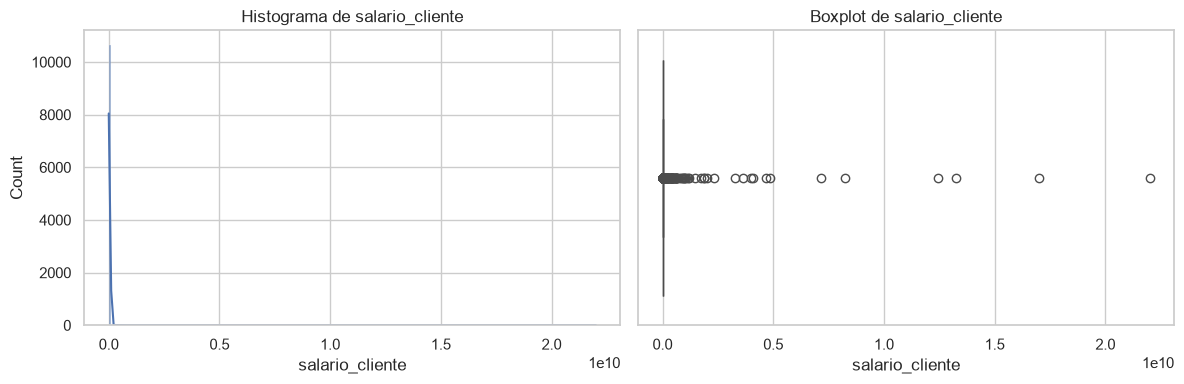

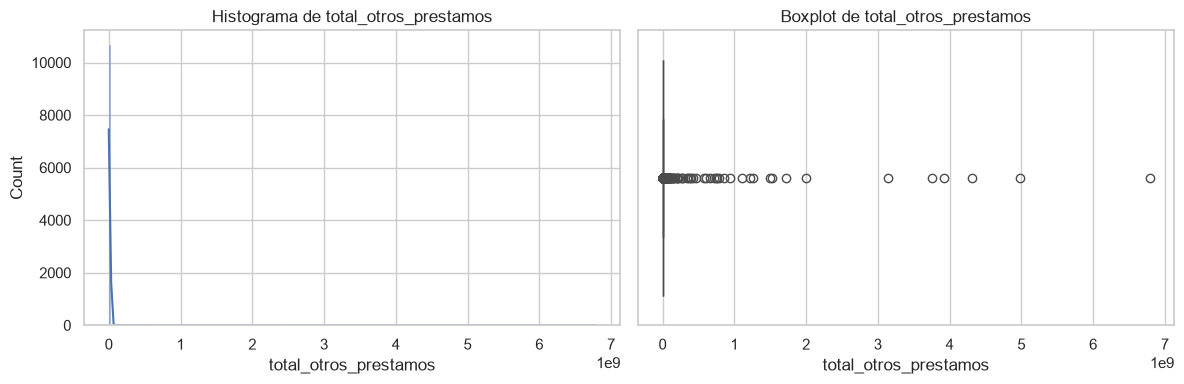

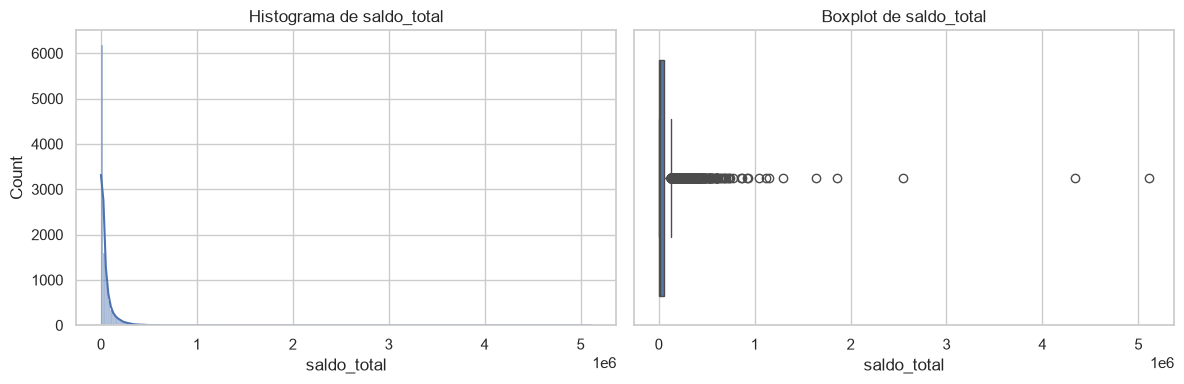

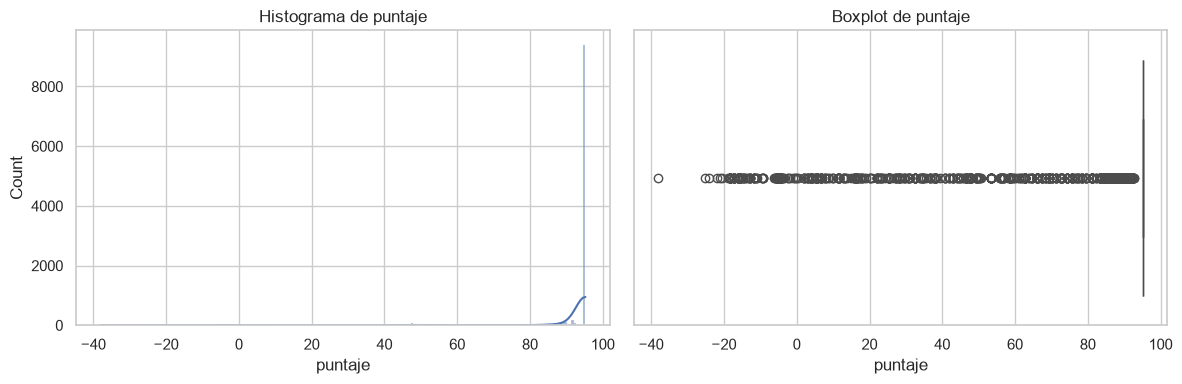

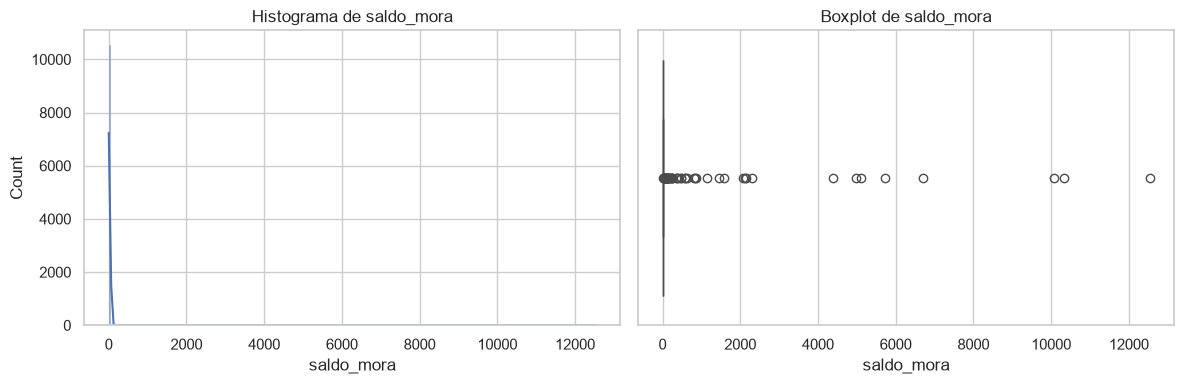

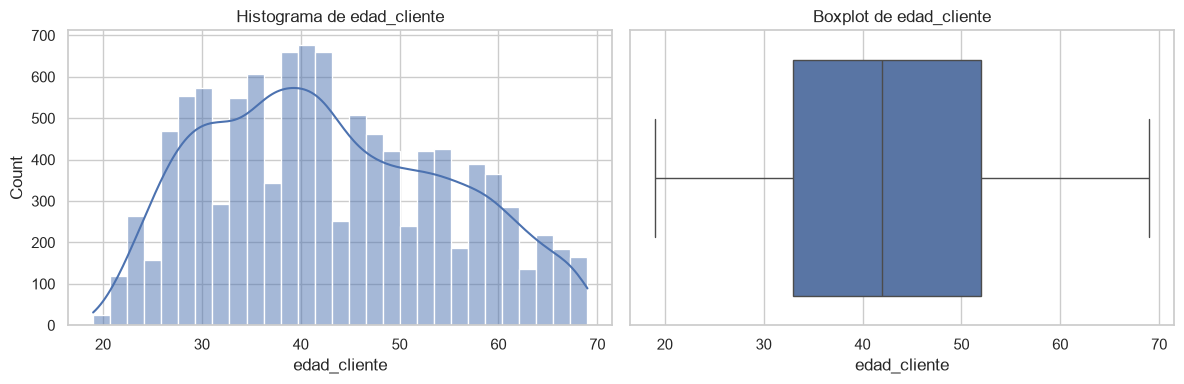

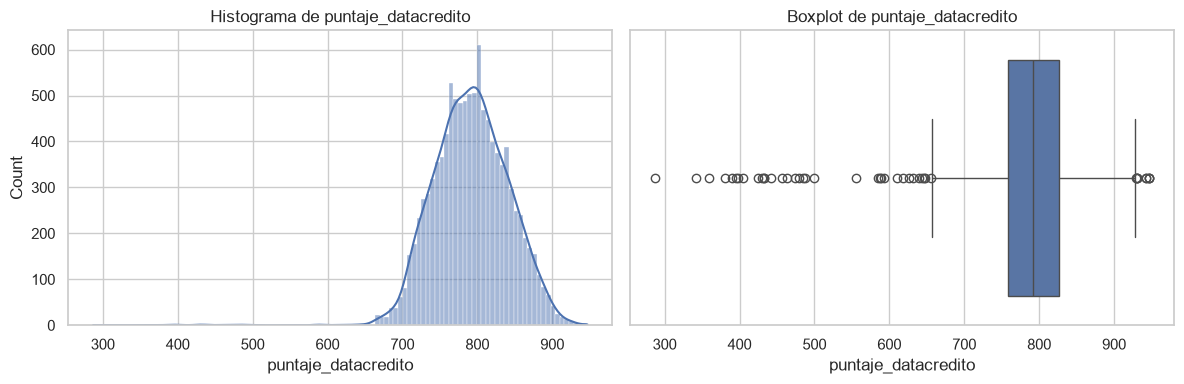

In [26]:
variables_graficar = [
    # Variables con inconsistencias
    "salario_cliente",          # asimetría extrema, salarios de hasta 22.000 millones
    "total_otros_prestamos",    # asimetría extrema
    "saldo_total",              # asimetría fuerte, media casi el triple de la mediana
    "puntaje",                  # asimetría negativa y valores negativos
    "saldo_mora",               # casi constante

    # Variables sanas
    "edad_cliente",             # simétrica, sin outliers
    "puntaje_datacredito",      # cercana a la normal
]

for columna in variables_graficar:
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[columna], kde=True, ax=ejes[0])
    ejes[0].set_title(f"Histograma de {columna}")
    sns.boxplot(x=df[columna], ax=ejes[1])
    ejes[1].set_title(f"Boxplot de {columna}")
    plt.tight_layout()
    plt.show()

**Interpretación:**
**Variables monetarias** (`salario_cliente`, `total_otros_prestamos`, `saldo_total`, `capital_prestado`, `cuota_pactada`): tienen asimetría positiva fuerte y muchos valores atípicos. La media es muy superior a la mediana; por ejemplo, en `salario_cliente` la media es de 17,2 millones y la mediana de 3 millones, con salarios de hasta 22.000 millones. Su forma se parece a una distribución log-normal (muchos valores bajos y pocos muy altos), por lo que se propone una transformación logarítmica.

**`puntaje`:** tiene asimetría negativa: el 87 % de los clientes tiene el valor máximo (95,23) y unos pocos tienen valores bajos o negativos. Como es un puntaje interno de escala desconocida, los negativos no se tratan como errores.

**`saldo_mora`:** casi todos los valores son 0; los pocos clientes con mora aparecen como valores atípicos.

**`edad_cliente`:** es aproximadamente simétrica (media 42,9 y mediana 42) y no tiene valores atípicos.

**`puntaje_datacredito`:** tiene forma de campana, cercana a una distribución normal (mediana 792). Sus 43 valores atípicos están dentro de la escala de Datacrédito (150-950): son clientes reales con mal historial crediticio, por lo que se conservan.

### Variables categóricas

--- tipo_credito ---
              clientes  porcentaje_%
tipo_credito                        
4                 7747         71.98
9                 2876         26.72
10                 116          1.08
6                   21          0.20
7                    2          0.02
68                   1          0.01



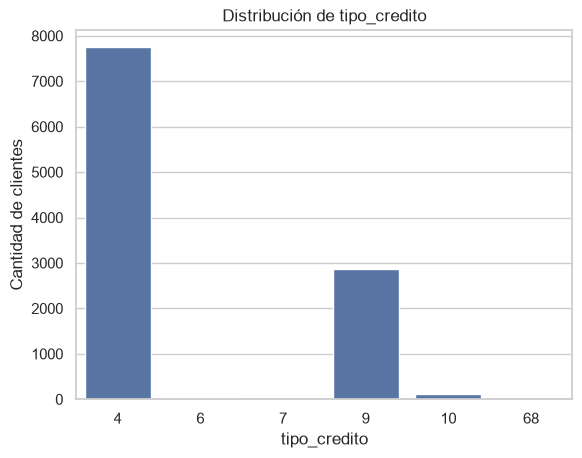

--- tipo_laboral ---
               clientes  porcentaje_%
tipo_laboral                         
Empleado           6754         62.75
Independiente      4009         37.25



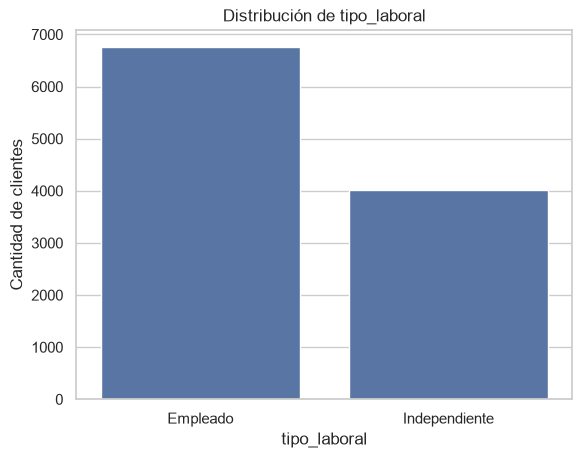

--- tendencia_ingresos ---
                    clientes  porcentaje_%
tendencia_ingresos                        
Creciente               5294         68.11
Decreciente             1291         16.61
Estable                 1188         15.28



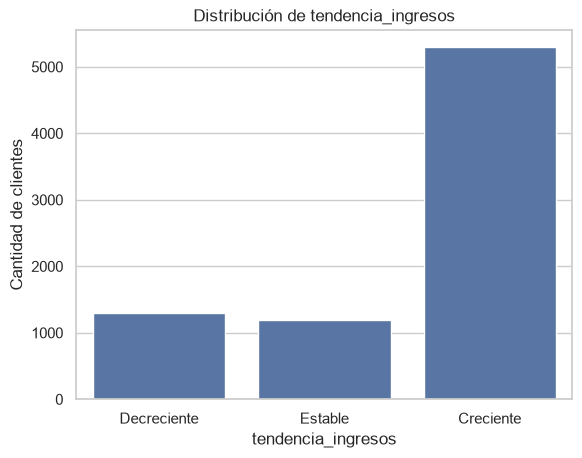

In [27]:
categoricas = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]

for columna in categoricas:
    tabla = pd.DataFrame({
        "clientes": df[columna].value_counts(),
        "porcentaje_%": (df[columna].value_counts(normalize=True) * 100).round(2)
    })
    print(f"--- {columna} ---")
    print(tabla)
    print()

    sns.countplot(data=df, x=columna)
    plt.title(f"Distribución de {columna}")
    plt.ylabel("Cantidad de clientes")
    plt.show()

**Interpretación de variables categóricas:**

**`tipo_credito`:** Los datos estan muy concentrados: los tipos 4 (72,0 %) y 9 (26,7 %) suman cerca del 99 % de los créditos. Mientras los tipos 6, 7 y 68 tienen muy pocos registros (21, 2 y 1), insuficientes para que el modelo aprenda de ellos, podiamos agrupar estos datos y poder crear otro dato llamdo Otros para no dejarlos por fuera.

**`tipo_laboral`:** el 62,8 % de los clientes son empleado y el 37,2 % independiente. Ambas categorías tienen representación suficiente.

**`tendencia_ingresos`:** entre los clientes con información, predomina la tendencia creciente con un 68,1 %, seguida decreciente con un 16,6 % y estable con 15,3 %. Esta variable tiene un 27,8 % de valores faltantes, que deberán tratarse

## Análisis bivariable
Se analiza la relación de cada variable con la variable objetivo `Pago_atiempo`, para identificar cuáles diferencian a los clientes que pagan a tiempo de los que no.


In [28]:
medianas = df.groupby("Pago_atiempo")[numericas].median().T
medianas.columns = ["No paga a tiempo (0)", "Paga a tiempo (1)"]
medianas

,No paga a tiempo (0),Paga a tiempo (1)
capital_prestado,"2,268,000.00","1,908,446.40"
plazo_meses,10.00,10.00
edad_cliente,37.00,42.00
salario_cliente,"3,000,000.00","3,000,000.00"
total_otros_prestamos,"900,000.00","1,000,000.00"
cuota_pactada,"199,002.00","182,576.00"
puntaje,25.42,95.23
puntaje_datacredito,769.00,792.00
cant_creditosvigentes,5.00,5.00
huella_consulta,5.00,4.00


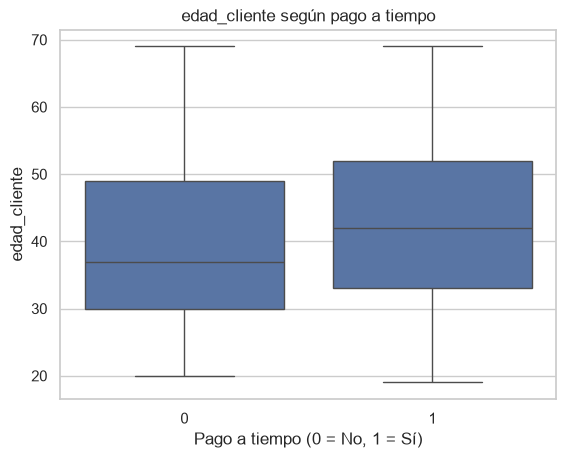

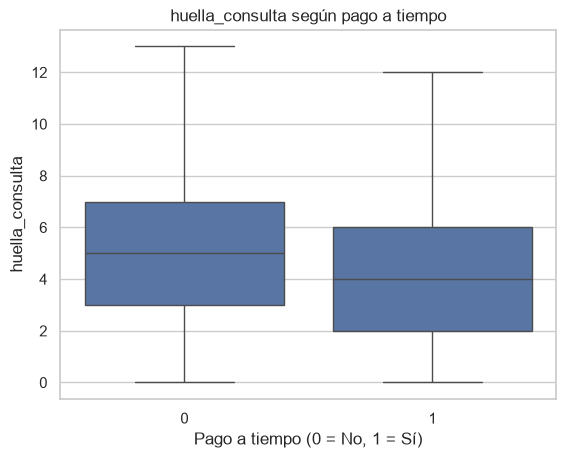

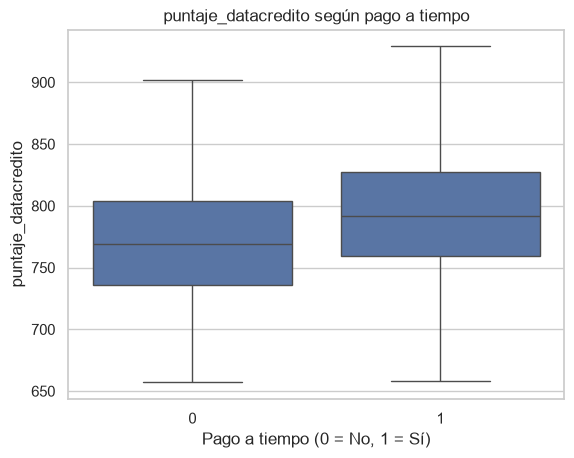

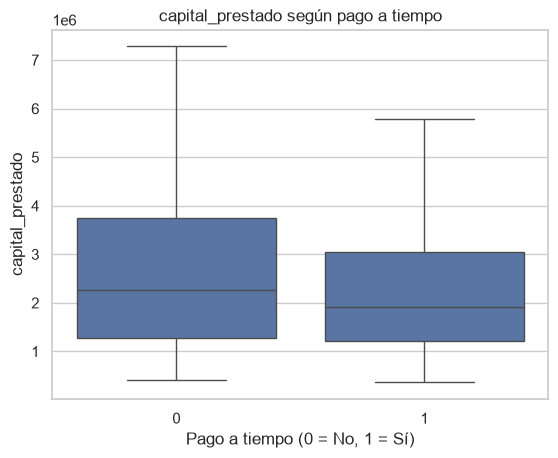

In [29]:
variables_bivariable = ["edad_cliente", "huella_consulta", "puntaje_datacredito", "capital_prestado"]

for columna in variables_bivariable:
    sns.boxplot(data=df, x="Pago_atiempo", y=columna, showfliers=False)
    plt.title(f"{columna} según pago a tiempo")
    plt.xlabel("Pago a tiempo (0 = No, 1 = Sí)")
    plt.show()

**Interpretación:**

Al comparar las medianas de cada grupo, se observa que los clientes que no pagan a tiempo son **más jóvenes**, con una mediana de 37 años, frente a los 42 años del grupo que paga a tiempo. Además, tienen **más consultas en centrales de riesgo** (`huella_consulta`), con una mediana de 5 frente a 4, lo que podría indicar una búsqueda más activa de créditos.

Por otro lado, presentan un **menor puntaje en Datacrédito**, con una mediana de 769 frente a 792, lo que sugiere un historial crediticio menos favorable. Asimismo, solicitaron **montos más altos** (`capital_prestado`), con una mediana de 2,27 millones frente a 1,91 millones, tienen **cuotas mayores** y registran **menores ingresos según Datacrédito**, con una mediana de 1,05 millones frente a 1,21 millones.

En cambio, las variables `salario_cliente`, `plazo_meses` y `cant_creditosvigentes` presentan la misma mediana en ambos grupos, por lo que, de manera individual, podrían aportar poca información para diferenciarlos. Sin embargo, esto no descarta que sean útiles en combinación con otras variables.

En general, las diferencias observadas son coherentes con la lógica del negocio, ya que sugieren un mayor riesgo de incumplimiento en clientes más jóvenes, con un historial crediticio menos favorable, mayores montos de crédito solicitados y menores ingresos.

In [30]:
for columna in categoricas:
    tabla = pd.crosstab(df[columna], df["Pago_atiempo"], normalize="index") * 100
    tabla.columns = ["% No paga a tiempo", "% Paga a tiempo"]
    tabla["clientes"] = df[columna].value_counts()
    print(f"--- {columna} ---")
    print(tabla.round(1))
    print()

--- tipo_credito ---
              % No paga a tiempo  % Paga a tiempo  clientes
tipo_credito                                               
4                           4.70            95.30      7747
6                          42.90            57.10        21
7                           0.00           100.00         2
9                           4.70            95.30      2876
10                          2.60            97.40       116
68                          0.00           100.00         1

--- tipo_laboral ---
               % No paga a tiempo  % Paga a tiempo  clientes
tipo_laboral                                                
Empleado                     4.30            95.70      6754
Independiente                5.50            94.50      4009

--- tendencia_ingresos ---
                    % No paga a tiempo  % Paga a tiempo  clientes
tendencia_ingresos                                               
Decreciente                       6.30            93.70      1291
Estable

**Interpretación**

El porcentaje general de no pago es del 4,75 %.

**`tipo_credito`:** Los tipos 4 y 9, que concentran casi el 99 % de los clientes, presentan el mismo porcentaje de no pago (4,7 %), cercano al promedio general. El tipo 6 muestra un 42,9 % de no pago; sin embargo, como solo cuenta con 21 clientes, este resultado debe interpretarse con cautela. Los tipos 7 y 68, con 2 y 1 cliente, respectivamente, no permiten obtener conclusiones confiables.

Esto refuerza la idea de **agrupar las categorías poco frecuentes**.

**`tipo_laboral`:** Los trabajadores independientes presentan un porcentaje de no pago ligeramente mayor (5,5 %) que los empleados (4,3 %). Aunque la diferencia es pequeña, se observa en grupos con un número considerable de clientes.

**`tendencia_ingresos`:** El porcentaje de no pago aumenta a medida que la tendencia de los ingresos empeora: creciente (3,9 %), estable (4,6 %) y decreciente (6,3 %).

Este comportamiento es coherente con la lógica del negocio y confirma el carácter ordinal de la variable, lo que justifica su codificación ordinal.

### Hallazgo: posible fuga de información en `puntaje`
En el análisis de medianas, `puntaje` mostró una diferencia muy superior a la de las demás variables (25,4 frente a 95,2). Se analiza en detalle si esta variable separa a los dos grupos.

In [31]:
df.groupby("Pago_atiempo")["puntaje"].describe()

,count,mean,std,min,25%,50%,75%,max
Pago_atiempo,,,,,,,,
0,511.00,23.09,26.07,-38.01,-3.59,25.42,47.61,62.67
1,"10,252.00",94.56,2.87,63.81,95.23,95.23,95.23,95.23


In [32]:
print("Puntaje MÁXIMO de quienes NO pagan:", df.loc[df["Pago_atiempo"] == 0, "puntaje"].max())
print("Puntaje MÍNIMO de quienes SÍ pagan:", df.loc[df["Pago_atiempo"] == 1, "puntaje"].min())

Puntaje MÁXIMO de quienes NO pagan: 62.667613
Puntaje MÍNIMO de quienes SÍ pagan: 63.809656


### Hallazgo: posible fuga de información en `puntaje`

La variable `puntaje` permite diferenciar claramente a los dos grupos. Todos los clientes que no pagaron a tiempo tienen un puntaje igual o menor a 62,67, mientras que todos los que sí pagaron tienen un puntaje igual o mayor a 63,81. Además, su correlación con la variable objetivo es de 0,92, muy superior a la de las demás variables. La siguiente es `puntaje_datacredito`, con 0,12.

Esta separación tan clara llama la atención, ya que no es lo habitual en un problema de riesgo crediticio. Por eso, existe la posibilidad de que `puntaje` contenga información relacionada directamente con el resultado del pago, lo que se conoce como **fuga de información**.

**Decisión:** Se excluye la variable `puntaje` del modelo para evitar que los resultados sean engañosos y que el modelo parezca funcionar mejor de lo que realmente podría hacerlo al utilizarse con nuevos clientes.

## Análisis multivariable

### Matriz de correlación

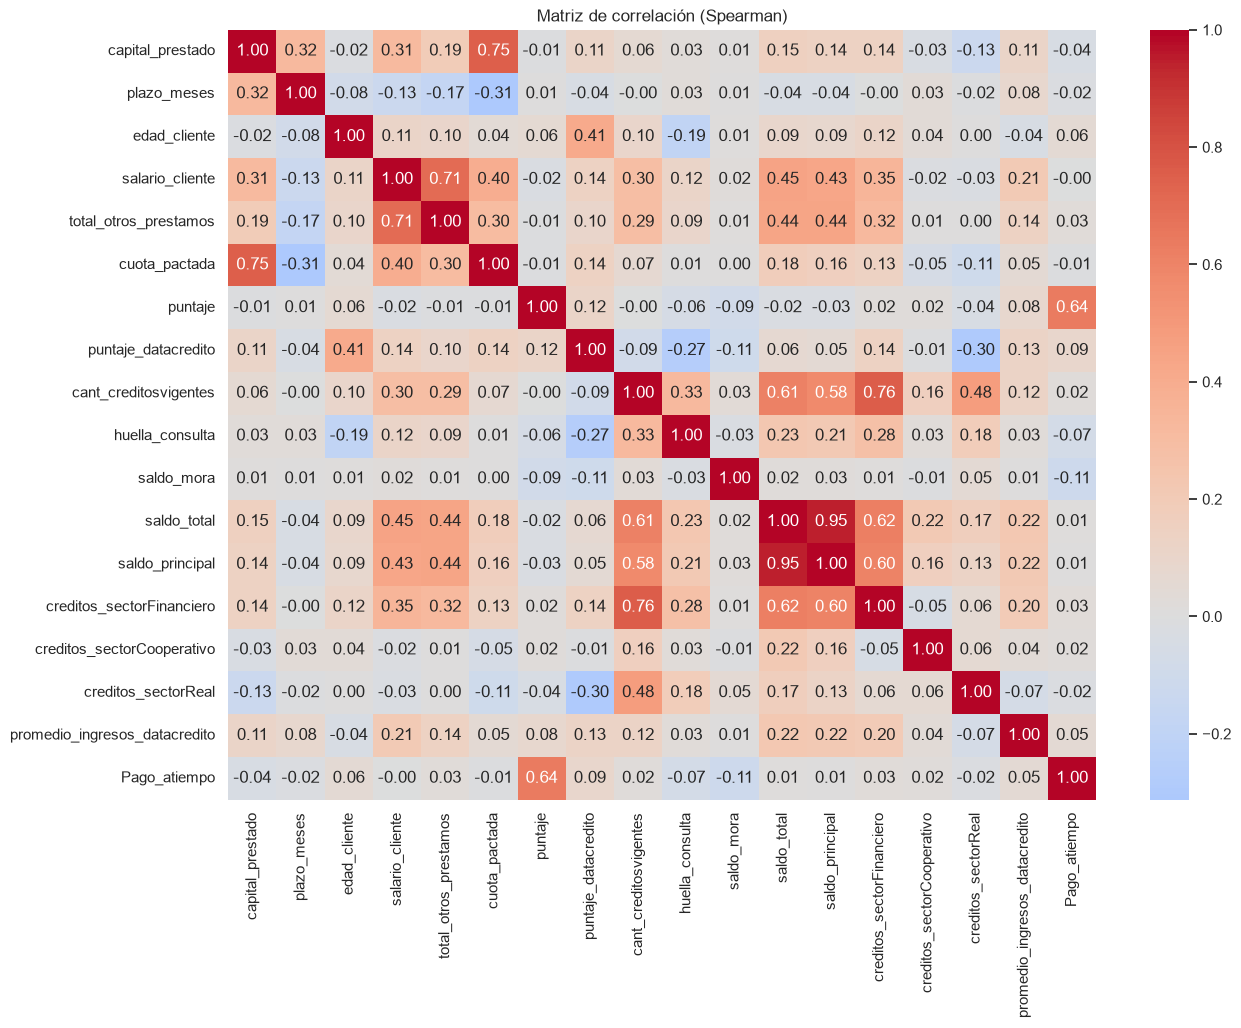

In [33]:
correlacion = df[numericas.tolist() + ["Pago_atiempo"]].corr(method="spearman")

plt.figure(figsize=(14, 10))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (Spearman)")
plt.show()

In [34]:
pares = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool)).stack()
pares.sort_values(key=abs, ascending=False).head(10)

saldo_total            saldo_principal             0.95
cant_creditosvigentes  creditos_sectorFinanciero   0.76
capital_prestado       cuota_pactada               0.75
salario_cliente        total_otros_prestamos       0.71
puntaje                Pago_atiempo                0.64
saldo_total            creditos_sectorFinanciero   0.62
cant_creditosvigentes  saldo_total                 0.61
saldo_principal        creditos_sectorFinanciero   0.60
cant_creditosvigentes  saldo_principal             0.58
                       creditos_sectorReal         0.48
dtype: float64

**Interpretación:**

Las variables `saldo_total` y `saldo_principal` tienen una correlación de 0,95, lo que significa que están muy relacionadas y contienen información similar. Por esta razón, se propone conservar `saldo_total`, ya que tiene menos valores faltantes (156 frente a 405), y excluir `saldo_principal` del modelo.

**`cant_creditosvigentes` y `creditos_sectorFinanciero`:** Presentan una correlación de 0,76. Esto tiene sentido, ya que los créditos del sector financiero hacen parte del total de créditos vigentes.

**`capital_prestado` y `cuota_pactada`:** Tienen una correlación de 0,75. Esto es coherente, porque, generalmente, cuanto mayor es el monto prestado, mayor es la cuota que debe pagar el cliente. A partir de estas variables.

**`salario_cliente` y `total_otros_prestamos`:** Presentan una correlación de 0,71, lo que indica que, en estos datos, los clientes con mayores ingresos también tienden a tener más préstamos.

Aunque estas relaciones son altas, no significa que las variables aporten exactamente la misma información. Por eso, se conservarán por ahora y se evaluará su utilidad durante el desarrollo del modelo.

En cuanto a la variable objetivo `Pago_atiempo`, la correlación más alta corresponde a `puntaje` (0,64), lo que refuerza la necesidad de revisar esta variable por la posible fuga de información identificada anteriormente. Las demás variables presentan correlaciones más bajas con el pago a tiempo, lo que sugiere que ninguna, por sí sola, permite explicar completamente si un cliente pagará o no. 

### Tabla cruzada: tipo laboral y tendencia de ingresos

In [35]:
tabla_cruzada = df.pivot_table(
    index="tipo_laboral",
    columns="tendencia_ingresos",
    values="Pago_atiempo",
    aggfunc=lambda x: (1 - x.mean()) * 100,
    observed=True
)
tabla_cruzada.round(1)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,5.90,4.50,3.60
Independiente,7.30,4.80,4.80


**Interpretación:**
 el riesgo de no pago aumenta cuando los ingresos del cliente van en descenso y es algo mayor en los independientes que en los empleados. Al combinar ambas variables, la diferencia se hace más clara es un independiente con ingresos decrecientes tiene el doble de riesgo (7,3 %) que un empleado con ingresos crecientes (3,6 %). Esto muestra que las variables aportan más información juntas que por separadas.





Teniendo en cuenta los resultados anteriores podemos decir ¿a qué tipo de cliente le falta más el dato de tendencia_ingresos?

In [36]:
(df.groupby("tipo_laboral", observed=True)["tendencia_ingresos"]
   .apply(lambda x: x.isnull().mean() * 100)
   .round(1))

tipo_laboral
Empleado        19.70
Independiente   41.50
Name: tendencia_ingresos, dtype: float64

**Interpretación:**
Esto nos muestra que a las personas independientes nos hace falta informacion relacionada a la tendecia de ingresoa 

### Gráfico con hue: capital vs cuota

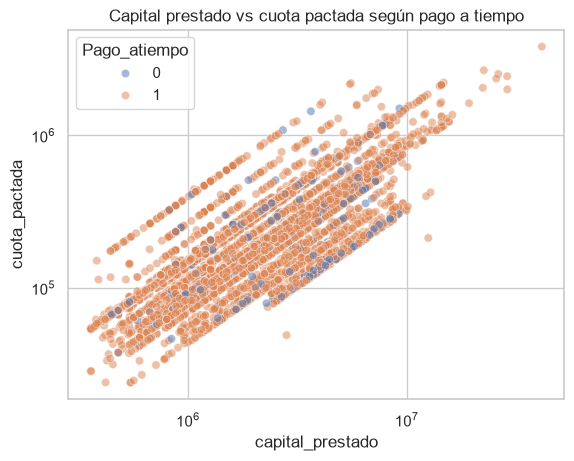

In [37]:
sns.scatterplot(data=df, x="capital_prestado", y="cuota_pactada",
                hue="Pago_atiempo", alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.title("Capital prestado vs cuota pactada según pago a tiempo")
plt.show()

**Interpretación:** 
existe una relación positiva entre el capital prestado y la cuota pactada, es decir. A mayor monto, mayor cuota. Las líneas paralelas que se observan corresponden a los distintos plazos (a mayor plazo, menor cuota para un mismo capital). Los clientes que no pagan a tiempo (azul) aparecen mezclados con los demás, sin concentrarse en una zona, por lo que estas dos variables por sí solas no permiten distinguirlos.

## Conclusiones del EDA

**Sobre la calidad de los datos.** Antes de utilizar la base para entrenar el modelo, es necesario realizar una limpieza. Se encontraron valores incorrectos o inconsistentes en variables como la edad, los puntajes de Datacrédito, los salarios y la tendencia de los ingresos. Esto puede deberse a errores al registrar o integrar la información. Por eso, es importante establecer reglas de validación que permitan detectar estos errores automáticamente cuando se reciban nuevos datos.

**Sobre el problema que se quiere predecir.** Predecir qué clientes no pagarán a tiempo representa un reto, principalmente porque solo el 4,75 % de los clientes pertenece a este grupo. Esto significa que el modelo tendrá menos ejemplos para aprender a identificar a los clientes que no pagan. Además, utilizar únicamente el *accuracy* podría dar una impresión equivocada sobre su desempeño. Aunque existen diferencias entre los clientes que pagan y los que no, ninguna variable por sí sola permite distinguirlos completamente. Por eso, el modelo deberá combinar diferentes características para identificar mejor los posibles casos de incumplimiento.

**Sobre el perfil de riesgo.** Los resultados muestran algunas diferencias entre los clientes que pagan a tiempo y los que no. Por ejemplo, el porcentaje de no pago es mayor entre los clientes más jóvenes, con puntajes crediticios más bajos, más consultas en centrales de riesgo, mayores montos solicitados, menores ingresos y una tendencia decreciente en sus ingresos. Estos hallazgos son coherentes con lo que se esperaría en un análisis de riesgo crediticio, aunque será necesario comprobar qué tan útiles son estas variables durante el entrenamiento del modelo.

**Sobre las variables que no deben utilizarse.** La variable `puntaje` presenta una separación demasiado clara entre los clientes que pagan y los que no. Esto genera sospechas de una posible fuga de información, es decir, que la variable podría contener información relacionada con el resultado que se quiere predecir. Si se incluye sin revisar su origen, el modelo podría mostrar resultados muy buenos durante el entrenamiento, pero no funcionar igual de bien con nuevos clientes. Por esta razón, se decidió excluirla. También se propone eliminar `saldo_principal`, ya que contiene información muy similar a `saldo_total` y, además, tiene más valores faltantes.

**Sobre los datos faltantes.** Se encontró que los valores faltantes no se distribuyen de la misma manera en todos los grupos. Por ejemplo, la tendencia de los ingresos falta con mayor frecuencia entre los trabajadores independientes. Esto podría aportar información útil sobre los clientes, por lo que es importante tenerlo en cuenta antes de completar los datos faltantes.


## Ideas y recomendaciones para la ejecucion de la ingenieria de caracteristicas

**Reglas de validación:** Establecer límites para detectar datos incorrectos, como edades entre 18 y 100 años y puntajes de Datacrédito entre 150 y 950. También se debe verificar que el salario, el capital prestado, la cuota y el plazo sean mayores que cero, que los saldos y las cantidades de créditos sean mayores o iguales a cero y que las categorías correspondan a los valores permitidos. Para `tipo_laboral`, se admitirán únicamente "Empleado" e "Independiente"; para `tendencia_ingresos`, "Creciente", "Estable", "Decreciente" o valores nulos, y para `Pago_atiempo`, únicamente 0 o 1.

**Transformaciones de las variables:**

- Excluir `puntaje` y `saldo_principal` del modelo. La variable `fecha_prestamo` se conservará para realizar seguimiento y analizar el comportamiento del modelo a lo largo del tiempo, pero no se utilizará inicialmente como variable predictora.
- Completar los valores faltantes de las variables numéricas utilizando la mediana y crear una categoría o indicador para identificar los registros sin información en `tendencia_ingresos`.
- Aplicar One-Hot Encoding a `tipo_laboral` y `tipo_credito`, agrupando previamente las categorías de crédito con pocos registros. Para `tendencia_ingresos`, utilizar una codificación ordinal que respete el orden de sus categorías.
- Aplicar transformaciones logarítmicas y escalado a las variables monetarias, para reducir su asimetría y llevarlas a rangos comparables.
- Manejar el desbalance de clases mediante una división estratificada de los datos, la ponderación de clases durante el entrenamiento y métricas como recall, F1 y AUC, en lugar de depender solo del accuracy.

**Atributos derivados:**

A partir de los hallazgos del análisis, se propone crear las siguientes variables:

-`ratio_cuota_salario` (cuota pactada / salario): mide la capacidad de pago del cliente, es decir, qué parte de sus ingresos se destina a la cuota. Surge de la relación entre el capital y la cuota observada en el análisis multivariable, y de que los clientes que no pagan solicitaron montos y cuotas más altos.

-`ratio_endeudamiento` (total de otros préstamos / salario): mide el nivel de endeudamiento del cliente frente a sus ingresos.

-`tiene_mora` (1 si `saldo_mora` es mayor que 0): resume en un indicador una variable casi constante, pero informativa, ya que los clientes con saldo en mora presentan un menor porcentaje de pago a tiempo.
-`tendencia_sin_info`(1 si falta `tendencia_ingresos`): conserva la información de que el dato no existía, dado que los valores faltantes son más frecuentes en los trabajadores independientes.